<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization**


Estimated time needed: **45** minutes


In this lab, you will focus on data visualization. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


After completing this lab, you will be able to:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize composition and comparison of data.




## Demo: How to work with database


Download the database file.


**Install and Import Necessary Python Libraries**

Ensure that you have the required libraries installed to work with SQLite and Pandas:


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Read the CSV File into a Pandas DataFrame**

Load the Stack Overflow survey data into a Pandas DataFrame:


In [3]:
# Read the CSV file
df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv')

# Display the first few rows of the data
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


**Create a SQLite Database and Insert the Data**

Now, let's create a new SQLite database (`survey-data.sqlite`) and insert the data from the DataFrame into a table using the sqlite3 library:


In [4]:
import sqlite3

# Create a connection to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Write the dataframe to the SQLite database
df.to_sql('main', conn, if_exists='replace', index=False)


# Close the connection
conn.close()


**Verify the Data in the SQLite Database**
Verify that the data has been correctly inserted into the SQLite database by running a simple query:


In [5]:
# Reconnect to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Run a simple query to check the data
QUERY = "SELECT * FROM main LIMIT 5"
df_check = pd.read_sql_query(QUERY, conn)

# Display the results
print(df_check)


   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

## Demo: Running an SQL Query


Count the number of rows in the table named 'main'


In [6]:
QUERY = """
SELECT COUNT(*) 
FROM main
"""
df = pd.read_sql_query(QUERY, conn)
df.head()


,COUNT(*)
0,65437


## Demo: Listing All Tables


To view the names of all tables in the database:


In [7]:
QUERY = """
SELECT name as Table_Name FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


## Demo: Running a Group By Query
    
For example, you can group data by a specific column, like Age, to get the count of respondents in each age group:


In [8]:
QUERY = """
SELECT Age, COUNT(*) as count
FROM main
GROUP BY Age
ORDER BY Age
"""
pd.read_sql_query(QUERY, conn)


,Age,count
0,18-24 years old,14098
1,25-34 years old,23911
2,35-44 years old,14942
3,45-54 years old,6249
4,55-64 years old,2575
5,65 years or older,772
6,Prefer not to say,322
7,Under 18 years old,2568


## Demo: Describing a table

Use this query to get the schema of a specific table, main in this case:


In [22]:
table_name = 'main'

QUERY = """
SELECT sql FROM sqlite_master 
WHERE name= '{}'
""".format(table_name)

df = pd.read_sql_query(QUERY, conn)

## Hands-on Lab


### Visualizing the Distribution of Data

**Histograms**

Plot a histogram of CompTotal (Total Compensation).


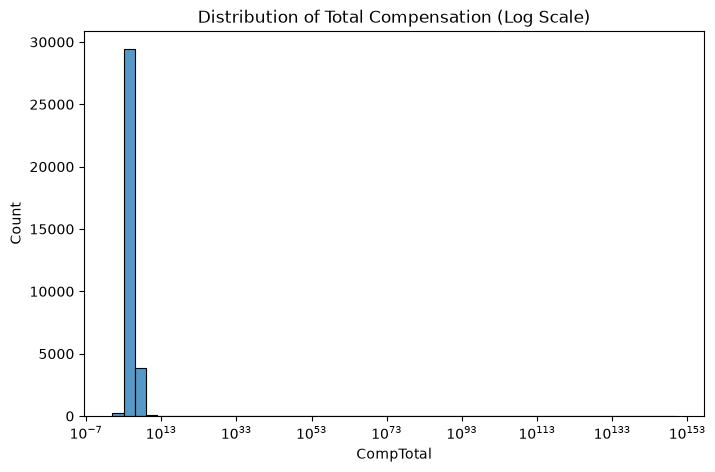

In [30]:
QUERY = """
SELECT CompTotal FROM main
WHERE CompTotal NOT NULL
"""

df = pd.read_sql_query(QUERY, conn)
df.head(5)

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df[df["CompTotal"] > 0],
    x="CompTotal",
    bins=50,
    log_scale=True
)

plt.title("Distribution of Total Compensation (Log Scale)")
plt.show()

**Box Plots**

Plot a box plot of Age.


                      Age
0      Under 18 years old
1         35-44 years old
2         45-54 years old
3         18-24 years old
4         18-24 years old
...                   ...
65432     18-24 years old
65433     25-34 years old
65434     25-34 years old
65435     18-24 years old
65436     18-24 years old

[65437 rows x 1 columns]


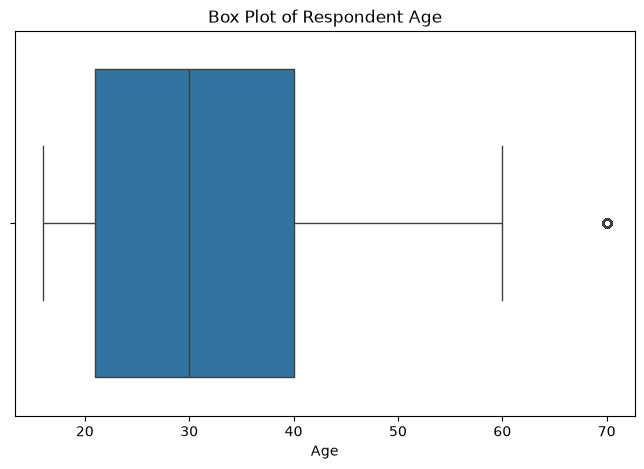

In [40]:
QUERY = """
SELECT Age FROM main
WHERE Age NOT NULL
"""

df_age = pd.read_sql_query(QUERY, conn)
print(df_age)

age_mapping = {
    "Under 18 years old": 16,
    "18-24 years old": 21,
    "25-34 years old": 30,
    "35-44 years old": 40,
    "45-54 years old": 50,
    "55-64 years old": 60,
    "65 years or older": 70
}

df_age["Age_numeric"] = df_age["Age"].map(age_mapping)

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_age, x="Age_numeric")

plt.title("Box Plot of Respondent Age")
plt.xlabel("Age")
plt.show()

### Visualizing Relationships in Data

**Scatter Plots**

Create a scatter plot of Age and WorkExp.


Text(0.5, 1.0, 'Scatter Plot Age vs. WorkExp')

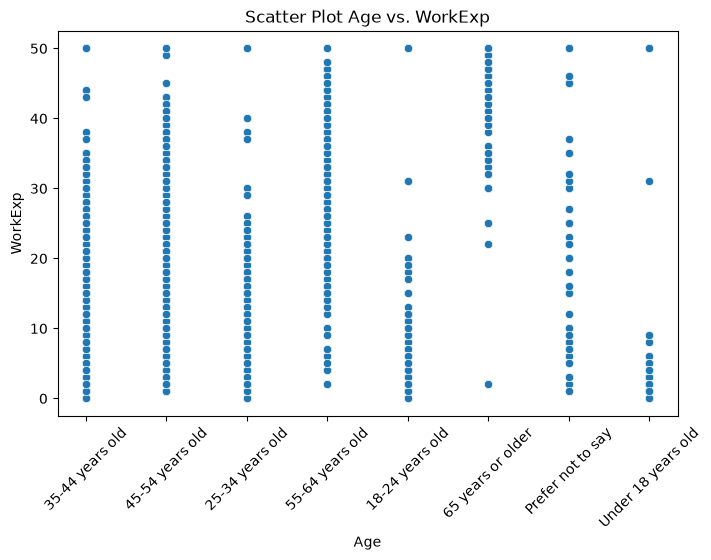

In [44]:
# Get query
QUERY = """
SELECT Age, WorkExp FROM main
WHERE Age NOT NULL AND WorkExp NOT NULL
"""

df_age_workexp = pd.read_sql_query(QUERY, conn)

# Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_age_workexp, x="Age", y="WorkExp")
plt.xticks(rotation=45)
plt.title("Scatter Plot Age vs. WorkExp")

**Bubble Plots**

Create a bubble plot of `TimeSearching` and `Frustration` using the Age column as the bubble size.


In [51]:
# Get query
QUERY = """
SELECT Age, TimeSearching, Frustration FROM main
WHERE Age NOT NULL AND TimeSearching NOT NULL AND Frustration NOT NULL
"""

df_age_bubble = pd.read_sql_query(QUERY, conn)

### Visualizing Composition of Data

**Pie Charts**

Create a pie chart of the top 5 databases(`DatabaseWantToWorkWith`) that respondents wish to learn next year.


In [54]:
QUERY = """
SELECT DatabaseWantToWorkWith FROM main
WHERE DatabaseWantToWorkWith NOT NULL
"""

df_db = pd.read_sql_query(QUERY, conn)
df_db

,DatabaseWantToWorkWith
0,PostgreSQL
1,Firebase Realtime Database
2,MongoDB;MySQL;PostgreSQL
3,PostgreSQL;SQLite
4,Cloud Firestore
...,...
42553,Dynamodb
42554,BigQuery;Cassandra;Databricks SQL;DuckDB;Elast...
42555,Elasticsearch;PostgreSQL;Redis
42556,PostgreSQL;SQLite


In [55]:
database_counts = (
    df_db["DatabaseWantToWorkWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
)

database_counts

DatabaseWantToWorkWith
PostgreSQL                    24005
SQLite                        13489
MySQL                         12269
MongoDB                       10982
Redis                         10847
Microsoft SQL Server           7905
Elasticsearch                  6246
MariaDB                        5947
Dynamodb                       3503
Supabase                       2930
Oracle                         2636
BigQuery                       2554
Firebase Realtime Database     2536
Cassandra                      2399
Cloud Firestore                2119
Snowflake                      1784
Cosmos DB                      1764
Neo4J                          1570
DuckDB                         1468
Clickhouse                     1328
Databricks SQL                 1218
Cockroachdb                    1157
InfluxDB                       1090
H2                             1040
Microsoft Access                662
Couch DB                        620
Solr                            558
Fireb

In [57]:
# Select the top 5 databases
top_5_databases = database_counts.head(5)
top_5_databases

DatabaseWantToWorkWith
PostgreSQL    24005
SQLite        13489
MySQL         12269
MongoDB       10982
Redis         10847
Name: count, dtype: int64

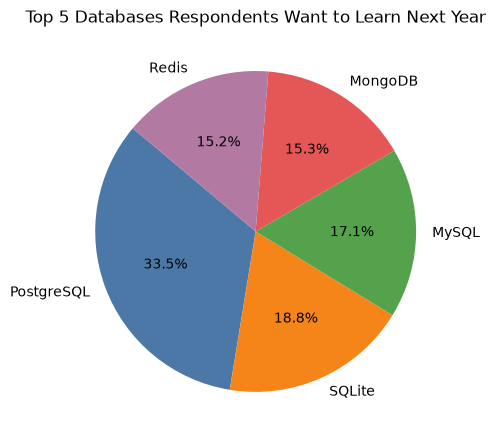

In [63]:
# Create pie chart
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2"]

plt.figure(figsize=(5, 5))
plt.pie(
    top_5_databases.values,
    labels=top_5_databases.index,
    autopct="%1.1f%%",
    colors=colors,
    startangle=140
)

plt.title("Top 5 Databases Respondents Want to Learn Next Year")
plt.tight_layout()
plt.show()

**Stacked Charts** 

Create a stacked bar chart of median `TimeSearching` and `TimeAnswering` for the age group 30 to 35.


In [69]:
QUERY = """
SELECT TimeSearching, TimeAnswering FROM main
WHERE TimeSearching NOT NULL AND 
    TimeAnswering NOT NULL AND
    Age = "25-34 years old"
"""

df_stacked = pd.read_sql_query(QUERY, conn)
df_stacked

,TimeSearching,TimeAnswering
0,15-30 minutes a day,30-60 minutes a day
1,Less than 15 minutes a day,15-30 minutes a day
2,60-120 minutes a day,15-30 minutes a day
3,60-120 minutes a day,15-30 minutes a day
4,30-60 minutes a day,15-30 minutes a day
...,...,...
12514,15-30 minutes a day,15-30 minutes a day
12515,60-120 minutes a day,15-30 minutes a day
12516,60-120 minutes a day,30-60 minutes a day
12517,Less than 15 minutes a day,Less than 15 minutes a day


### Visualizing Comparison of Data

**Line Chart**

Plot the median `CompTotal` for all ages from 45 to 60.


In [ ]:
## Write your code here

**Bar Chart**

Create a horizontal bar chart using the `MainBranch` column.


In [ ]:
## Write your code here

### Summary


In this lab, you focused on extracting and visualizing data from an RDBMS using SQL queries and SQLite. You applied various visualization techniques, including:

- Histograms to display the distribution of CompTotal.
- Box plots to show the spread of ages.
- Scatter plots and bubble plots to explore relationships between variables like Age, WorkExp, `TimeSearching` and `TimeAnswering`.
- Pie charts and stacked charts to visualize the composition of data.
- Line charts and bar charts to compare data across categories.


### Close the Database Connection

Once the lab is complete, ensure to close the database connection:


In [72]:
conn.close()

## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
